# 3. WordPiece

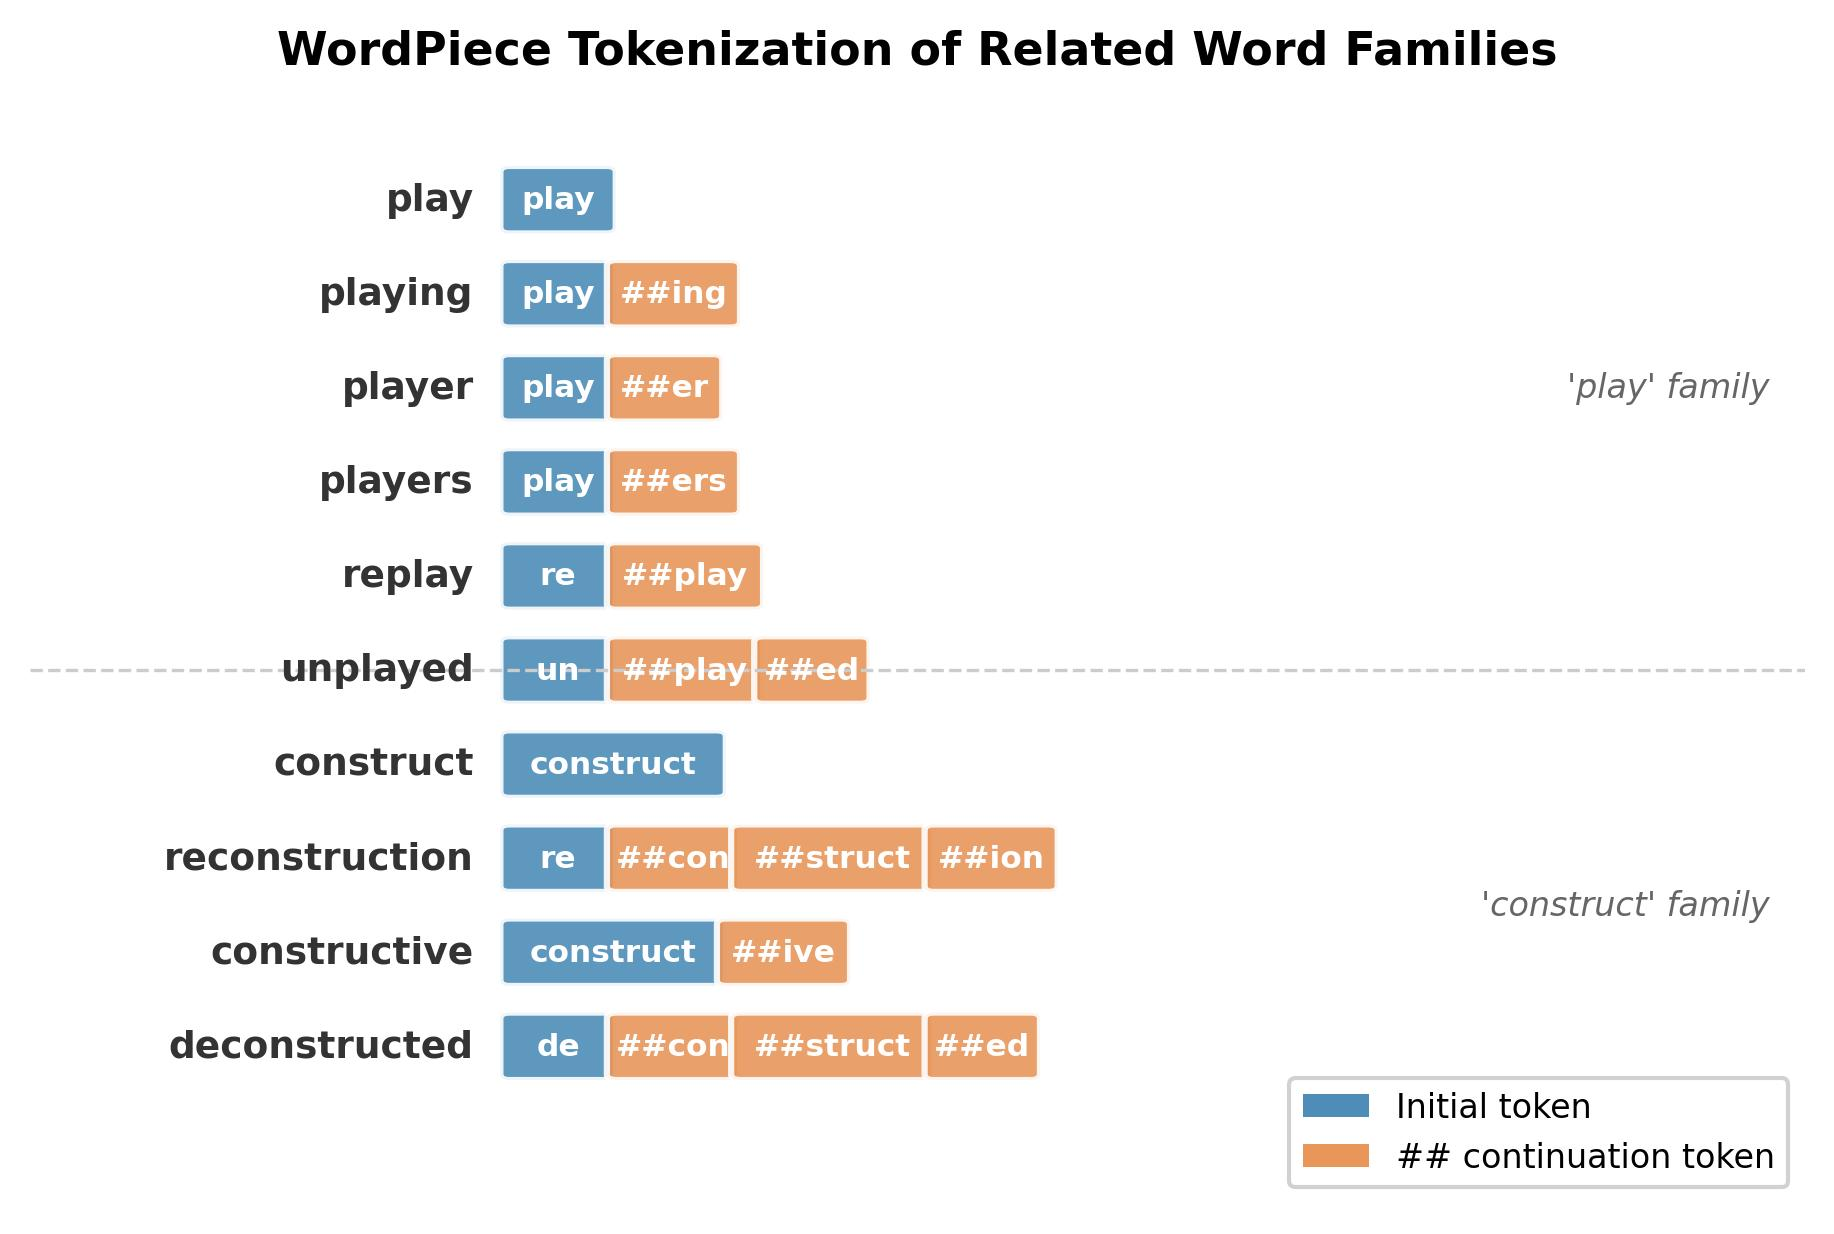

**WordPiece** is another important **subword tokenization algorithm**, most famously associated with **BERT** and its descendants such as DistilBERT and ELECTRA.

The key idea is:

> **Represent a word using the longest vocabulary pieces that can be matched from left to right.**



---

## 3.1 WordPiece and BERT

When you hear:

```text
BERT
 ↓
WordPiece
```

that's an important association to remember.

The original BERT model uses **WordPiece tokenization**. Modern Hugging Face documentation also identifies `BertTokenizer` as being based on WordPiece.

For example:

```text
"I am playing football"
```

might become:

```text
["i", "am", "playing", "football"]
```

if those words exist in the vocabulary.

But for a word that isn't stored as a complete vocabulary entry:

```text
"playing"
```

it could become:

```text
["play", "##ing"]
```

The `##` tells us:

> **This token continues the previous subword; it does not begin a new word.**

---

# 3.2 WordPiece Vocabulary

A WordPiece vocabulary contains both:

### Beginning-of-word tokens

```text
play
player
playful
construct
ing
```

and continuation tokens:

```text
##ing
##er
##ful
##ion
##ed
```

The distinction matters.

For example:

```text
playing
```

can be represented as:

```text
play + ##ing
```

while:

```text
replaying
```

might be represented as:

```text
re + ##play + ##ing
```



The `##` is **notation used by WordPiece token vocabularies** to indicate that the piece occurs inside/after the beginning of a word. Hugging Face's tokenizer implementation uses `##` as the default continuing-subword prefix. [Hugging Face](https://huggingface.co/docs/tokenizers/python/latest/api/reference.html?highlight=bertpretokenizer\&utm_source=chatgpt.com)

---

# 3.3 Why `##`?

This is one of the easiest things to get asked in an interview.

Consider:

```text
["play", "##ing"]
```

The tokenizer tells us:

```text
play      → starts a word
##ing     → continues that word
```

So we can reconstruct:

```text
play + ing
     ↓
playing
```

Compare:

```text
["playing"]
```

with:

```text
["play", "##ing"]
```

The second representation explicitly tells us that `##ing` is attached to the previous token.

### Important

`##` is **not part of the actual English word**.

It is a marker used by the tokenizer vocabulary/decoder.

---

# 3.4 Greedy Matching

Now we get to the most important algorithmic idea.

WordPiece uses a **greedy longest-match-first strategy** for tokenizing a word. Google describes this as **MaxMatch**: repeatedly select the longest vocabulary token matching the remaining prefix.

Suppose our vocabulary contains:

```text
play
player
##er
##ing
##ed
```

and we encounter:

```text
playing
```

The tokenizer starts from the beginning.

### Step 1

Remaining text:

```text
playing
^^^^^^^
```

Look for the **longest vocabulary item** that matches the beginning.

Suppose:

```text
playing
play
```

`play` matches.

So:

```text
playing
 ↓
play
```

Remaining:

```text
ing
```

### Step 2

Because we're now inside the word, we look for a continuation token:

```text
##ing
```

It matches.

Therefore:

```text
playing
 ↓
["play", "##ing"]
```

---

# 3.5 Another Example

Suppose vocabulary contains:

```text
un
##believable
##able
##liev
##ing
```

Consider:

```text
unbelievable
```

The tokenizer starts from the left:

```text
unbelievable
^^
```

It finds:

```text
un
```

Then:

```text
believable
^^^^^^^^^^
```

Suppose the vocabulary contains:

```text
##believable
```

Then it chooses that rather than splitting unnecessarily:

```text
["un", "##believable"]
```

The principle is:

> **At each position, choose the longest valid vocabulary piece.**

---

# 3.6 What if the Longest Match Doesn't Exist?

Suppose:

```text
Vocabulary:

play
##ing
##er
##ed
##ful
```

and we encounter:

```text
playfulness
```

Maybe the tokenizer can find:

```text
play
```

then:

```text
##ful
```

but eventually encounters:

```text
ness
```

If no valid continuation sequence can represent the remaining text, the WordPiece tokenizer may produce:

```text
[UNK]
```

for the word rather than arbitrarily falling back to individual characters, depending on the vocabulary/tokenizer configuration. Hugging Face's BERT tokenizer uses `[UNK]` for tokens that cannot be represented by its vocabulary.

This is a useful distinction from byte-level approaches we'll encounter later.

---

# 3.7 WordPiece vs BPE

You should **not** think:

> "WordPiece is just BPE with `##`."

They're related, but their vocabulary-learning procedures differ.

| Property | BPE | WordPiece |
|---|---|---|
| Type | Subword | Subword |
| Used by famous models | GPT-style models, Llama-family, etc. | **BERT-family** |
| Basic idea | Merge frequent pairs | Learn useful subword vocabulary |
| Tokenization | Apply learned merges | **Greedy longest-match** |
| Continuation marker | Implementation-dependent | **`##`** in BERT-style WordPiece |
| Pair selection during training | Frequency-based in classic BPE | Likelihood-based objective |
| OOV handling | Depends on implementation | `[UNK]` possible |

Hugging Face specifically notes that BPE merges the most frequent pair, while WordPiece chooses merges based on a likelihood-related score during training. [Hugging Face](https://huggingface.co/docs/transformers/tokenizer_summary?utm_source=chatgpt.com)

So:

```text
BPE
Training:
"Which pair occurs most frequently?"

WordPiece
Training:
"Which merge improves the likelihood most?"

Tokenization:
"What's the longest vocabulary piece I can match here?"
```

The **training algorithm** and **tokenization algorithm** are separate concepts.

---

# 3.8 BPE vs WordPiece: Don't Mix These Up

This distinction is important for interviews.

### BPE

Conceptually:

```text
characters
    ↓
count pairs
    ↓
merge most frequent
    ↓
new vocabulary
    ↓
repeat
```

### WordPiece

Conceptually:

```text
training corpus
    ↓
learn useful vocabulary
    ↓
WordPiece vocabulary
    ↓
NEW WORD
    ↓
greedy longest matching
    ↓
subword tokens
```

So if I ask:

> **"How does WordPiece tokenize a word?"**

Your answer should be:

> It uses a greedy longest-match-first strategy, selecting the longest vocabulary token that matches the remaining part of the word, with `##` marking continuation subwords.

That's the answer I want you to remember. 🎯

---

# 3.9 Why WordPiece Works Well for BERT

Consider these related words:

```text
play
playing
played
player
players
```

A word-level vocabulary might need:

```text
play
playing
played
player
players
```

WordPiece can share representations:

```text
play
##ing
##ed
##er
##s
```

giving representations such as:

```text
playing  → play + ##ing
played   → play + ##ed
player   → play + ##er
players  → play + ##er + ##s
```

This allows BERT to work with many rare or previously unseen combinations using a relatively compact vocabulary.

---

# 3.10 A Visual Mental Model

Think of WordPiece as **cutting a word from left to right using the largest available pieces**.

```text
Input:

unbelievable
│
├── un
│
└──── believable
       │
       └── ##believable
```

Or:

```text
playing
│
├── play
│
└──── ##ing
```

The process is:

```text
START
  │
  ▼
Find longest vocabulary token
  │
  ▼
Take it
  │
  ▼
Move forward
  │
  ▼
Find longest continuation token
  │
  ▼
Repeat
```

This is why the term **greedy** is used.

---

# 3.11 The Important Caveat About "Greedy"

Greedy does **not** mean:

> "Choose whatever token is globally best."

It means:

> **Make the best local choice at the current position — specifically, the longest valid match — without exploring every possible segmentation.**

For example:

```text
Input:
abcdef
```

If the vocabulary contains:

```text
abc
ab
cdef
```

a greedy longest-match tokenizer may choose:

```text
abc
```

first because it is the longest match at the beginning.

It doesn't necessarily search all possible tokenizations to find some globally optimal segmentation.

This is an important algorithmic distinction.

---

# 3.12 WordPiece in the BERT Pipeline

You already know the Transformer architecture, so connect WordPiece to the existing pipeline:

```text
Raw text
   ↓
Normalization / preprocessing
   ↓
WordPiece tokenizer
   ↓
Subword tokens
   ↓
Token IDs
   ↓
Token embeddings
   ↓
BERT Encoder
   ↓
Contextual representations
   ↓
Downstream task
```

For example:

```text
"I am playing cricket"
             ↓
["i", "am", "play", "##ing", "cricket"]
             ↓
[1045, 2572, ..., ..., ...]
             ↓
BERT
```

The tokenizer therefore determines **what the Transformer actually sees as its input sequence**.

---

## Must Know ⭐

- **WordPiece is strongly associated with BERT.**
- BERT uses a **WordPiece vocabulary**. 
- WordPiece represents words using **subword units**.
- `##` indicates a **continuation subword**.
- Example:
  ```text
  playing → play + ##ing
  ```
- WordPiece tokenization uses **greedy longest-match-first** matching. 
- `[UNK]` can be produced when a word cannot be represented using the available vocabulary. 
- WordPiece and BPE are related, but their **training/objective and tokenization mechanisms differ**.

### Good to Know

- `##` is a tokenizer convention, not part of the original text.
- WordPiece vocabulary contains both beginning-of-word and continuation pieces.
- The Hugging Face `WordPiece` implementation uses `##` as its default continuation prefix. 
- Google's **MaxMatch** terminology describes the greedy longest-match approach.

### Optional / Advanced

- WordPiece training objective
- Maximum matching complexity
- Trie-based WordPiece tokenization
- **LinMaxMatch**, Google's linear-time optimization for WordPiece tokenization. [Google Research](https://research.google/blog/a-fast-wordpiece-tokenization-system/?hl=in\&utm_source=chatgpt.com)

---

## What you should remember

1. **BERT → WordPiece** is the key association.
2. WordPiece uses a **subword vocabulary**.
3. During tokenization, it uses **greedy longest matching**.
4. `##` means **"this subword continues the previous word."**
5. `playing → play + ##ing` is the canonical mental example.
6. **BPE chooses frequent merges; WordPiece tokenization uses longest-match-first.**
7. `[UNK]` can still occur when a word cannot be represented by the vocabulary.

---